# Soybean Price Forecasting: ARIMA vs SARIMA — Indore and Gondal
Same workflow as the Groundnut SARIMA notebook (data check → ADF → ACF/PACF → 80:20 split → ARIMA → SARIMA), extended with parameter tuning (AIC/BIC), residual tests, DM test, naive benchmark, rolling-origin backtesting, confidence intervals, future forecast, month-wise error, rise/fall accuracy and Excel export.

**Both markets are run one after the other in every step.**

**Files to upload (one upload box):** the Indore price csv (`price_indore_market_cleaned_ffill_no_holidays_covid.csv`) and the Rajkot/Gondal price file (`price_data_cleaned_rajkot.xlsx`).

## 0. Libraries, settings and data upload

In [1]:
!pip -q install holidays openpyxl
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, itertools, time, glob, os
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix
import holidays
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})

# ======================= SETTINGS (change here only) =======================
PRICE_COL      = 'p_modal'   # 'p_modal', 'p_min' or 'p_max'
TEST_FRAC      = 0.20        # 80:20 train-test split (as in the template)
IC             = 'aic'       # criterion used to pick the best order: 'aic' or 'bic'
ARIMA_MAX_PQ   = 3           # ARIMA grid: p, q = 0..3
SARIMA_MAX_PQ  = 2           # SARIMA grid: p, q = 0..2
SARIMA_MAX_PQs = 1           # SARIMA grid: P, Q = 0..1
SEASONAL_M     = {}          # e.g. {'Indore': 6, 'Gondal': 6}; empty = auto (observations per week)
D_OVERRIDE     = None        # None = choose d from ADF+KPSS on the training data; or set 0 / 1 / 2
ROLL_WINDOW    = 30          # window (observations) for the rolling mean / std
N_FOLDS        = 8           # rolling-origin backtest: number of origins
ROLL_H         = 10          # rolling-origin backtest: forecast horizon (observations) at each origin
FUTURE_H       = 30          # future forecast horizon (trading days)
REMOVE_COVID   = True        # remove the two COVID closure windows
REMOVE_HOLIDAYS= True        # remove public holidays / festival days (Madhya Pradesh list)
COVID = [('2020-03-22', '2020-05-17'), ('2021-04-09', '2021-06-13')]
# ===========================================================================

try:
    from google.colab import files
    uploaded = files.upload(); names = list(uploaded.keys())
except ImportError:                                   # running outside Colab
    names = [f for f in glob.glob('*') if f.lower().endswith(('.csv', '.xlsx', '.xls'))]

def pick(*keys):
    c = [n for n in names if any(k in n.lower() for k in keys) and 'arrival' not in n.lower()]
    return c[-1] if c else None
SOURCES = {'Indore': pick('indore'), 'Gondal': pick('gondal', 'rajkot')}
print(SOURCES)
assert all(SOURCES.values()), 'Upload the Indore file and the Rajkot/Gondal file'
MARKETS = list(SOURCES)

Saving price_data_cleaned_rajkot.xlsx to price_data_cleaned_rajkot.xlsx
Saving price_indore_market_cleaned_ffill_no_holidays_covid.csv to price_indore_market_cleaned_ffill_no_holidays_covid.csv
{'Indore': 'price_indore_market_cleaned_ffill_no_holidays_covid.csv', 'Gondal': 'price_data_cleaned_rajkot.xlsx'}


### Reading and cleaning rules (same as the Indore file we prepared)
* one row per date (average if a date repeats),
* missing days are filled by **forward fill only** (last real price carried forward),
* Sundays with no data are dropped,
* the two COVID closure windows and the public-holiday / festival dates are removed (switches in the settings cell).

The Indore file is already cleaned, so these steps change nothing there (they are idempotent); for Gondal they are applied here.

In [2]:
def read_any(path, market):
    df = pd.read_excel(path) if path.lower().endswith(('.xlsx', '.xls')) else pd.read_csv(path)
    dcol = [c for c in df.columns if c.strip().lower() in ('date', 't')][0]
    df = df.rename(columns={dcol: 'date'})
    if not pd.api.types.is_datetime64_any_dtype(df['date']):
        first = str(df['date'].iloc[0])
        df['date'] = pd.to_datetime(df['date'], format='mixed', dayfirst=not first[:4].isdigit())
    if 'market_name' in df.columns:
        df = df[df['market_name'].astype(str).str.contains(market, case=False)]
    assert PRICE_COL in df.columns, f'{PRICE_COL} not found in {path}'
    return df[['date', PRICE_COL]].copy()

HOL = sorted({pd.Timestamp(k) for k in holidays.India(subdiv='MP', years=range(2011, 2036))})

def make_clean(s):
    real = s.dropna()
    cal = pd.date_range(real.index.min(), real.index.max())
    x = real.reindex(cal).ffill()                                    # forward fill only
    real_sun = set(real.index[real.index.dayofweek == 6])
    x = x[(x.index.dayofweek != 6) | x.index.isin(list(real_sun))]   # drop Sundays with no data
    drop = pd.Series(False, index=x.index)
    if REMOVE_COVID:
        for a, b in COVID: drop |= x.index.to_series().between(a, b)
    if REMOVE_HOLIDAYS:
        drop |= x.index.isin(HOL)
    return x[~drop.values]

RAW = {m: read_any(SOURCES[m], m) for m in MARKETS}

## 1. Missing values and duplicate-date checking

In [3]:
rows = []
for m in MARKETS:
    r = RAW[m]; d = r['date']
    cal = pd.date_range(d.min(), d.max())
    miss = cal.difference(pd.DatetimeIndex(d.unique()))
    miss_ns = miss[miss.dayofweek != 6]                        # missing days that are not Sundays
    run = pd.Series(miss); g = (run.diff() != pd.Timedelta('1D')).cumsum()
    longest = int(run.groupby(g).size().max()) if len(run) else 0
    rows.append([m, len(r), d.min().date(), d.max().date(), int(r[PRICE_COL].isna().sum()),
                 int(d.duplicated().sum()), len(miss), len(miss_ns), longest])
chk = pd.DataFrame(rows, columns=['market', 'rows', 'first date', 'last date', 'missing prices', 'duplicate dates',
                                  'missing calendar days', 'missing (excl. Sundays)', 'longest missing run (days)'])
print('--- RAW files as uploaded ---'); display(chk)

S = {}                                              # cleaned price series (one per market)
for m in MARKETS:
    s = RAW[m].groupby('date')[PRICE_COL].mean()    # one row per date
    S[m] = make_clean(s).astype(float)
    S[m].index.name = 'date'
after = pd.DataFrame({m: {'rows': len(S[m]), 'missing prices': int(S[m].isna().sum()),
                          'duplicate dates': int(S[m].index.duplicated().sum()),
                          'first': S[m].index.min().date(), 'last': S[m].index.max().date()} for m in MARKETS}).T
print('--- After cleaning (forward fill, Sundays/holidays/COVID removed) ---'); display(after)

--- RAW files as uploaded ---


,market,rows,first date,last date,missing prices,duplicate dates,missing calendar days,missing (excl. Sundays),longest missing run (days)
0,Indore,4386,2011-01-01,2025-12-31,0,0,1093,367,66
1,Gondal,4354,2011-01-03,2025-12-31,0,0,1123,341,4


--- After cleaning (forward fill, Sundays/holidays/COVID removed) ---


,rows,missing prices,duplicate dates,first,last
Indore,4386,0,0,2011-01-01,2025-12-31
Gondal,4328,0,0,2011-01-03,2025-12-31


## 2. Descriptive statistics

In [4]:
desc = pd.DataFrame({m: S[m].describe() for m in MARKETS}).T
desc['skew'] = [S[m].skew() for m in MARKETS]; desc['kurtosis'] = [S[m].kurt() for m in MARKETS]
desc['CV %'] = desc['std'] / desc['mean'] * 100
display(desc.round(2))
yearly = pd.DataFrame({m: S[m].groupby(S[m].index.year).mean() for m in MARKETS}).round(0)
print('Yearly average price (Rs/quintal):'); display(yearly)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,CV %
Indore,4386.0,3883.38,1197.80,1120.0,3200.0,3650.0,4300.0,10300.0,1.60,4.01,30.84
Gondal,4328.0,3716.70,1135.49,1580.0,3000.0,3500.0,4250.0,8555.0,1.23,1.97,30.55


Yearly average price (Rs/quintal):


,Indore,Gondal
date,,
2011,2190.0,2089.0
2012,3269.0,3105.0
2013,3465.0,3236.0
2014,3691.0,3469.0
2015,3396.0,3214.0
2016,3436.0,3244.0
2017,2873.0,2664.0
2018,3346.0,3055.0
2019,3659.0,3397.0


## 3. Soybean price trend graph

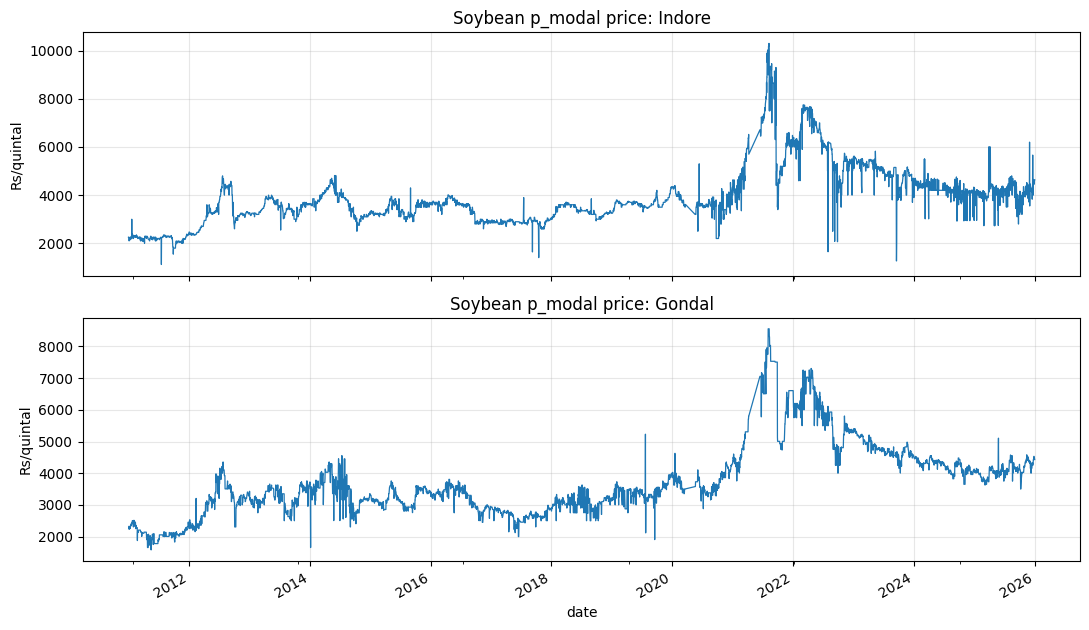

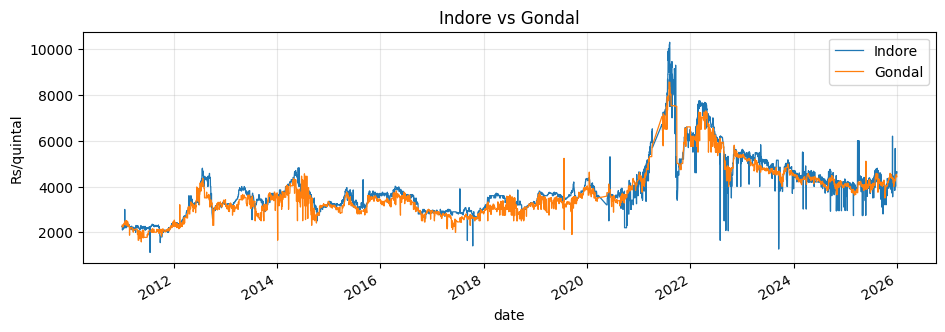

In [5]:
fig, ax = plt.subplots(len(MARKETS), 1, figsize=(11, 3.2*len(MARKETS)), sharex=True)
for a, m in zip(ax, MARKETS):
    S[m].plot(ax=a, lw=.9); a.set_title(f'Soybean {PRICE_COL} price: {m}'); a.set_ylabel('Rs/quintal')
plt.tight_layout(); plt.show()
plt.figure(figsize=(11, 3.4))
for m in MARKETS: S[m].plot(label=m, lw=.9)
plt.legend(); plt.title('Indore vs Gondal'); plt.ylabel('Rs/quintal'); plt.show()

## 4. Rolling mean and standard deviation

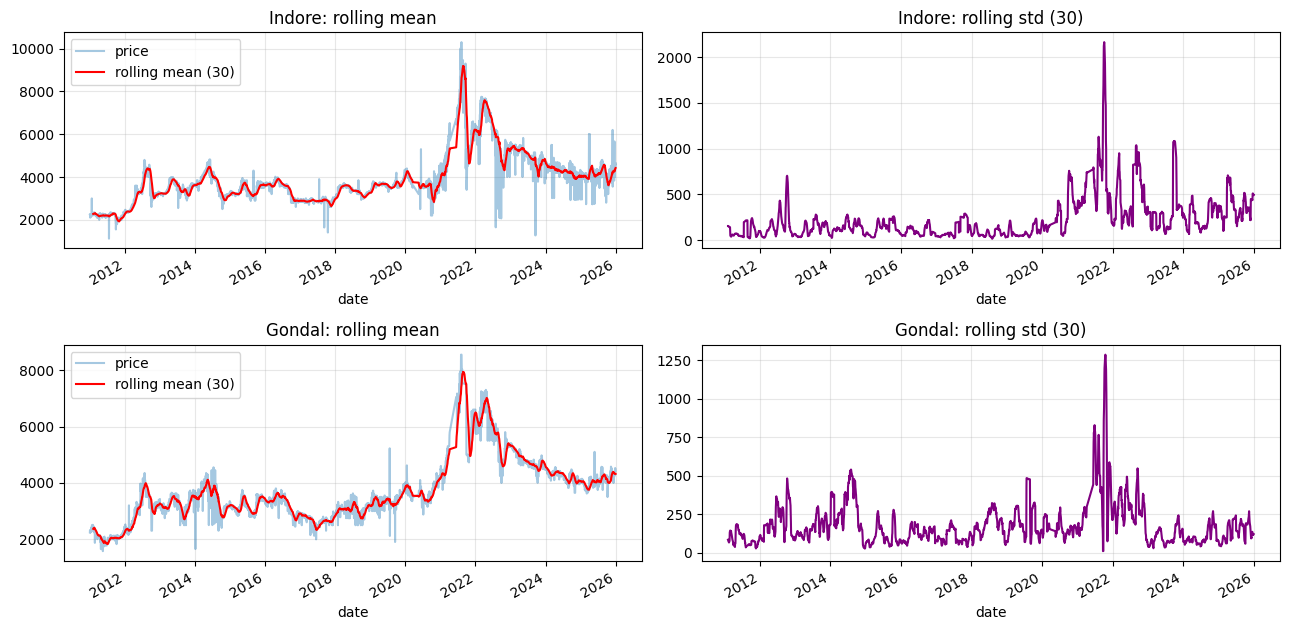

In [6]:
fig, ax = plt.subplots(len(MARKETS), 2, figsize=(13, 3.2*len(MARKETS)))
ax = np.atleast_2d(ax)
for i, m in enumerate(MARKETS):
    rm, rs = S[m].rolling(ROLL_WINDOW).mean(), S[m].rolling(ROLL_WINDOW).std()
    S[m].plot(ax=ax[i,0], alpha=.4, label='price'); rm.plot(ax=ax[i,0], color='red', label=f'rolling mean ({ROLL_WINDOW})')
    ax[i,0].set_title(f'{m}: rolling mean'); ax[i,0].legend()
    rs.plot(ax=ax[i,1], color='purple'); ax[i,1].set_title(f'{m}: rolling std ({ROLL_WINDOW})')
plt.tight_layout(); plt.show()

## 5. ADF stationarity test (plus KPSS)
ADF **H₀: unit root**; KPSS **H₀: stationary**. The differencing order **d** is chosen on the **training** data only: d = 0 if ADF rejects *and* KPSS does not reject, otherwise d = 1 (change with `D_OVERRIDE`).

In [7]:
V, DATES, NTR, TRAIN, TEST = {}, {}, {}, {}, {}
for m in MARKETS:
    V[m] = S[m].values.astype(float); DATES[m] = S[m].index
    NTR[m] = int(len(V[m]) * (1 - TEST_FRAC)); TRAIN[m] = V[m][:NTR[m]]; TEST[m] = V[m][NTR[m]:]

D_ORD = {}
rows = []
for m in MARKETS:
    tr = TRAIN[m]
    a0, a1, a2 = adfuller(tr)[1], adfuller(np.diff(tr))[1], adfuller(V[m])[1]
    k0 = kpss(tr, nlags='auto')[1]
    d = D_OVERRIDE if D_OVERRIDE is not None else (0 if (a0 < .05 and k0 > .05) else 1)
    D_ORD[m] = d
    rows.append([m, round(a2, 4), round(a0, 4), round(a1, 6), round(k0, 4), d])
display(pd.DataFrame(rows, columns=['market', 'ADF p (full series)', 'ADF p (train, level)', 'ADF p (train, 1st diff)',
                                    'KPSS p (train, level)', 'chosen d']))

,market,ADF p (full series),"ADF p (train, level)","ADF p (train, 1st diff)","KPSS p (train, level)",chosen d
0,Indore,0.0301,0.0627,0.0,0.01,1
1,Gondal,0.1892,0.2988,0.0,0.01,1


## 6. ACF and PACF plots (level and first difference)

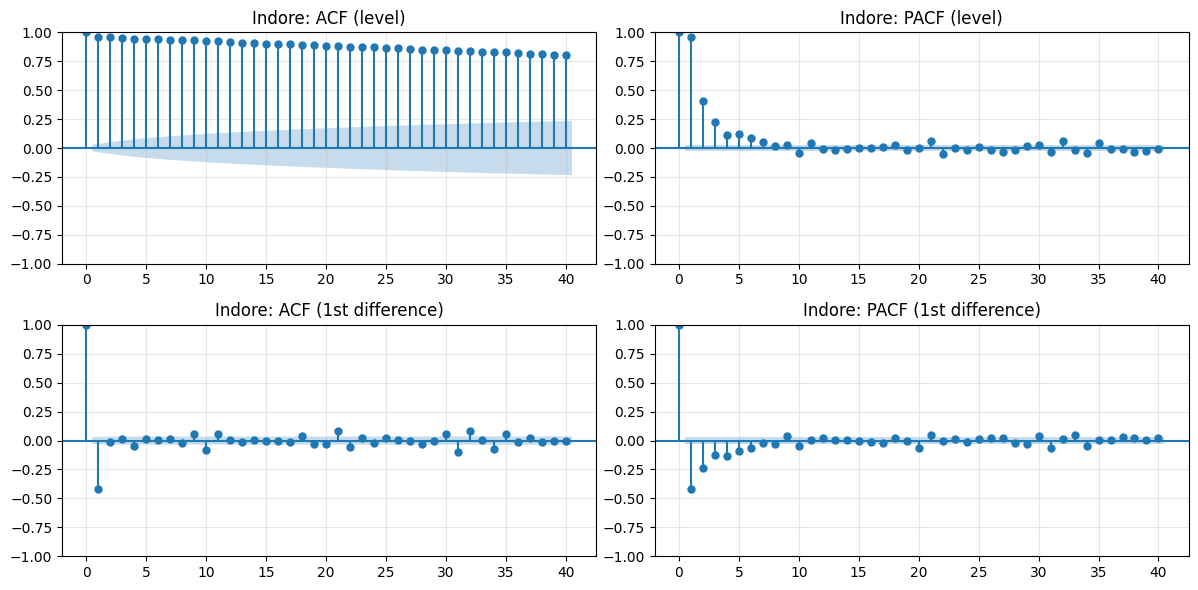

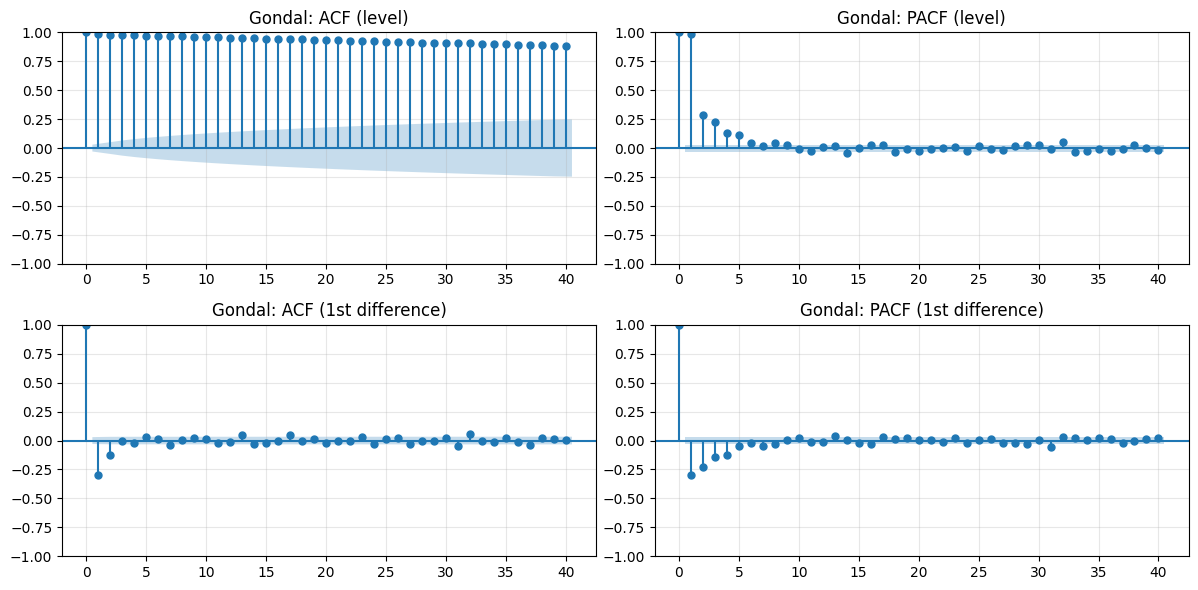

In [8]:
for m in MARKETS:
    fig, ax = plt.subplots(2, 2, figsize=(12, 6))
    plot_acf(V[m], lags=40, ax=ax[0,0], title=f'{m}: ACF (level)'); plot_pacf(V[m], lags=40, ax=ax[0,1], title=f'{m}: PACF (level)')
    plot_acf(np.diff(V[m]), lags=40, ax=ax[1,0], title=f'{m}: ACF (1st difference)'); plot_pacf(np.diff(V[m]), lags=40, ax=ax[1,1], title=f'{m}: PACF (1st difference)')
    plt.tight_layout(); plt.show()

## 7. Train–test split (80:20)

Indore: train 2011-01-01 -> 2023-02-11 (3508 obs) | test 2023-02-13 -> 2025-12-31 (878 obs) | 5.60 obs/week -> seasonal period m = 6
Gondal: train 2011-01-03 -> 2023-01-19 (3462 obs) | test 2023-01-20 -> 2025-12-31 (866 obs) | 5.53 obs/week -> seasonal period m = 6


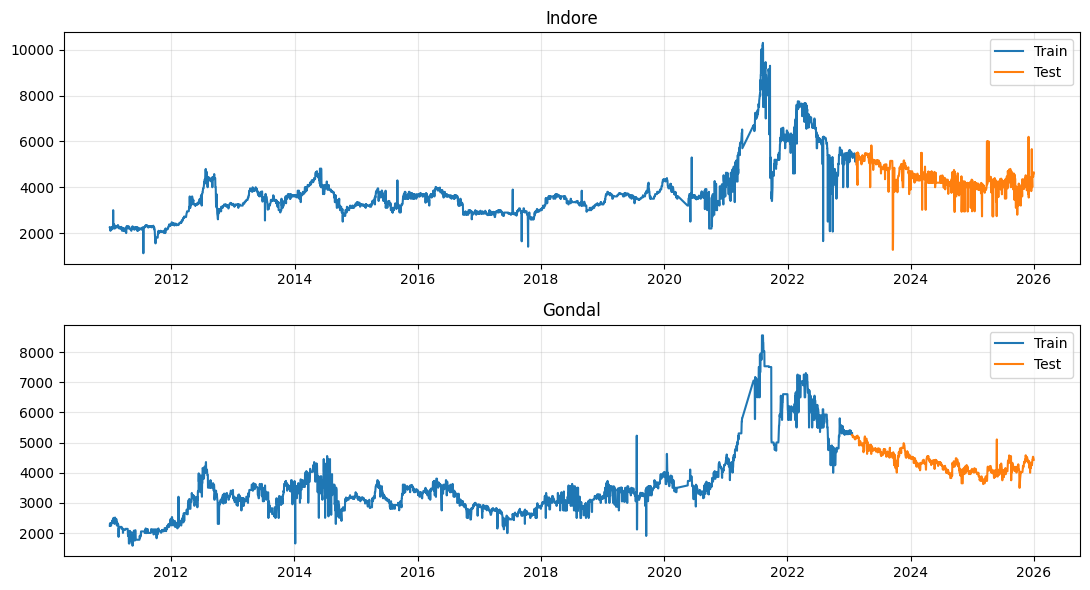

In [9]:
M_SEAS = {}
for m in MARKETS:
    yy = S[m]; per_week = len(yy) / ((yy.index[-1] - yy.index[0]).days / 7)
    M_SEAS[m] = SEASONAL_M.get(m, int(round(per_week)))
    print(f'{m}: train {DATES[m][0].date()} -> {DATES[m][NTR[m]-1].date()} ({NTR[m]} obs) | '
          f'test {DATES[m][NTR[m]].date()} -> {DATES[m][-1].date()} ({len(TEST[m])} obs) | '
          f'{per_week:.2f} obs/week -> seasonal period m = {M_SEAS[m]}')
fig, ax = plt.subplots(len(MARKETS), 1, figsize=(11, 3*len(MARKETS)))
for a, m in zip(np.atleast_1d(ax), MARKETS):
    a.plot(DATES[m][:NTR[m]], TRAIN[m], label='Train'); a.plot(DATES[m][NTR[m]:], TEST[m], label='Test'); a.legend(); a.set_title(m)
plt.tight_layout(); plt.show()

## 8. ARIMA parameter tuning (grid search)
Every (p, d, q) with p, q = 0…`ARIMA_MAX_PQ` is fitted on the **training** data; the best order is the one with the lowest `IC`.

In [10]:
def fit_sx(y, order, seas=(0, 0, 0, 0)):
    return SARIMAX(y, order=order, seasonal_order=seas).fit(disp=False)

def grid_arima(y, d, maxpq):
    out = []
    for p, q in itertools.product(range(maxpq + 1), range(maxpq + 1)):
        try:
            r = fit_sx(y, (p, d, q)); out.append([(p, d, q), r.aic, r.bic, r.llf])
        except Exception: pass
    return pd.DataFrame(out, columns=['order', 'AIC', 'BIC', 'logLik']).sort_values(IC.upper()).reset_index(drop=True)

ARIMA_GRID, BEST_ARIMA = {}, {}
for m in MARKETS:
    t0 = time.time(); ARIMA_GRID[m] = grid_arima(TRAIN[m], D_ORD[m], ARIMA_MAX_PQ); BEST_ARIMA[m] = ARIMA_GRID[m].loc[0, 'order']
    print(f'\n{m}: {len(ARIMA_GRID[m])} ARIMA models fitted in {time.time()-t0:.0f}s | best by {IC.upper()}: ARIMA{BEST_ARIMA[m]}')
    display(ARIMA_GRID[m].head(10).round(1))


Indore: 16 ARIMA models fitted in 21s | best by AIC: ARIMA(2, 1, 3)


,order,AIC,BIC,logLik
0,"(2, 1, 3)",48711.7,48748.7,-24349.8
1,"(3, 1, 3)",48712.9,48756.1,-24349.5
2,"(3, 1, 2)",48733.3,48770.2,-24360.6
3,"(2, 1, 2)",48735.1,48765.9,-24362.5
4,"(1, 1, 3)",48735.8,48766.6,-24362.9
5,"(1, 1, 2)",48738.3,48762.9,-24365.1
6,"(3, 1, 1)",48741.9,48772.8,-24366.0
7,"(0, 1, 1)",48742.4,48754.8,-24369.2
8,"(1, 1, 1)",48743.7,48762.2,-24368.9
9,"(0, 1, 2)",48743.8,48762.3,-24368.9



Gondal: 16 ARIMA models fitted in 12s | best by AIC: ARIMA(0, 1, 2)


,order,AIC,BIC,logLik
0,"(0, 1, 2)",46273.9,46292.4,-23134.0
1,"(2, 1, 1)",46275.5,46300.1,-23133.8
2,"(1, 1, 2)",46275.9,46300.5,-23134.0
3,"(0, 1, 3)",46275.9,46300.5,-23134.0
4,"(3, 1, 1)",46277.4,46308.1,-23133.7
5,"(1, 1, 3)",46277.8,46308.5,-23133.9
6,"(2, 1, 2)",46278.0,46308.7,-23134.0
7,"(3, 1, 2)",46279.5,46316.4,-23133.7
8,"(3, 1, 3)",46279.6,46322.7,-23132.8
9,"(2, 1, 3)",46279.7,46316.6,-23133.9


## 9. SARIMA parameter tuning (grid search)
(p, d, q) × (P, 0, Q, m) with p, q = 0…`SARIMA_MAX_PQ`, P, Q = 0…`SARIMA_MAX_PQs`; m = observations per week. This takes a few minutes.

In [11]:
def grid_sarima(y, d, m, maxpq, maxPQ):
    out = []
    for p, q, P, Q in itertools.product(range(maxpq + 1), range(maxpq + 1), range(maxPQ + 1), range(maxPQ + 1)):
        try:
            r = fit_sx(y, (p, d, q), (P, 0, Q, m)); out.append([(p, d, q), (P, 0, Q, m), r.aic, r.bic, r.llf])
        except Exception: pass
    return pd.DataFrame(out, columns=['order', 'seasonal_order', 'AIC', 'BIC', 'logLik']).sort_values(IC.upper()).reset_index(drop=True)

SARIMA_GRID, BEST_SARIMA = {}, {}
for m in MARKETS:
    t0 = time.time(); SARIMA_GRID[m] = grid_sarima(TRAIN[m], D_ORD[m], M_SEAS[m], SARIMA_MAX_PQ, SARIMA_MAX_PQs)
    BEST_SARIMA[m] = (SARIMA_GRID[m].loc[0, 'order'], SARIMA_GRID[m].loc[0, 'seasonal_order'])
    print(f'\n{m}: {len(SARIMA_GRID[m])} SARIMA models fitted in {time.time()-t0:.0f}s | best by {IC.upper()}: SARIMA{BEST_SARIMA[m][0]}x{BEST_SARIMA[m][1]}')
    display(SARIMA_GRID[m].head(10).round(1))


Indore: 36 SARIMA models fitted in 53s | best by AIC: SARIMA(2, 1, 2)x(1, 0, 1, 6)


,order,seasonal_order,AIC,BIC,logLik
0,"(2, 1, 2)","(1, 0, 1, 6)",48722.9,48766.0,-24354.5
1,"(1, 1, 2)","(1, 0, 1, 6)",48727.7,48764.6,-24357.8
2,"(2, 1, 2)","(1, 0, 0, 6)",48728.1,48765.1,-24358.1
3,"(2, 1, 2)","(0, 0, 1, 6)",48728.6,48765.6,-24358.3
4,"(1, 1, 2)","(0, 0, 1, 6)",48733.0,48763.8,-24361.5
5,"(2, 1, 2)","(0, 0, 0, 6)",48735.1,48765.9,-24362.5
6,"(0, 1, 1)","(1, 0, 1, 6)",48737.8,48762.5,-24364.9
7,"(1, 1, 2)","(0, 0, 0, 6)",48738.3,48762.9,-24365.1
8,"(0, 1, 2)","(1, 0, 1, 6)",48739.2,48770.0,-24364.6
9,"(1, 1, 1)","(1, 0, 1, 6)",48739.6,48770.4,-24364.8



Gondal: 36 SARIMA models fitted in 35s | best by AIC: SARIMA(0, 1, 2)x(0, 0, 0, 6)


,order,seasonal_order,AIC,BIC,logLik
0,"(0, 1, 2)","(0, 0, 0, 6)",46273.9,46292.4,-23134.0
1,"(0, 1, 2)","(0, 0, 1, 6)",46275.3,46299.9,-23133.7
2,"(0, 1, 2)","(1, 0, 0, 6)",46275.3,46299.9,-23133.7
3,"(2, 1, 1)","(0, 0, 0, 6)",46275.5,46300.1,-23133.8
4,"(1, 1, 2)","(0, 0, 0, 6)",46275.9,46300.5,-23134.0
5,"(2, 1, 1)","(1, 0, 0, 6)",46277.1,46307.9,-23133.6
6,"(1, 1, 2)","(0, 0, 1, 6)",46277.3,46308.1,-23133.7
7,"(1, 1, 2)","(1, 0, 0, 6)",46277.3,46308.1,-23133.7
8,"(0, 1, 2)","(1, 0, 1, 6)",46277.3,46308.1,-23133.7
9,"(2, 1, 1)","(0, 0, 1, 6)",46277.8,46308.5,-23133.9


## 10. AIC and BIC comparison

,market,model,specification,AIC,BIC,logLik,n_params
0,Indore,ARIMA,"ARIMA(2, 1, 3)",48711.7,48748.7,-24349.8,6
1,Indore,SARIMA,"SARIMA(2, 1, 2)x(1, 0, 1, 6)",48722.9,48766.0,-24354.5,7
2,Gondal,ARIMA,"ARIMA(0, 1, 2)",46273.9,46292.4,-23134.0,3
3,Gondal,SARIMA,"SARIMA(0, 1, 2)x(0, 0, 0, 6)",46273.9,46292.4,-23134.0,3


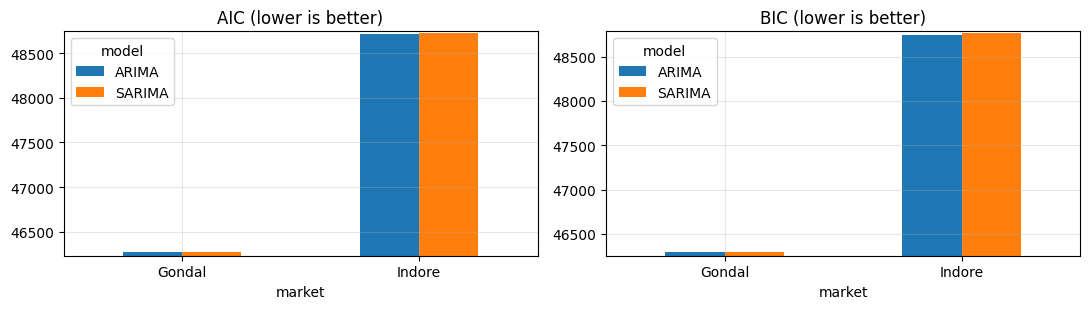

In [12]:
FIT = {}                                    # fitted best models on the training data
for m in MARKETS:
    FIT[(m, 'ARIMA')]  = fit_sx(TRAIN[m], BEST_ARIMA[m])
    FIT[(m, 'SARIMA')] = fit_sx(TRAIN[m], BEST_SARIMA[m][0], BEST_SARIMA[m][1])
rows = []
for m in MARKETS:
    for mod, spec in [('ARIMA', f'ARIMA{BEST_ARIMA[m]}'), ('SARIMA', f'SARIMA{BEST_SARIMA[m][0]}x{BEST_SARIMA[m][1]}')]:
        r = FIT[(m, mod)]; rows.append([m, mod, spec, r.aic, r.bic, r.llf, len(r.params)])
IC_TABLE = pd.DataFrame(rows, columns=['market', 'model', 'specification', 'AIC', 'BIC', 'logLik', 'n_params']).round(1)
display(IC_TABLE)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, crit in zip(ax, ['AIC', 'BIC']):
    IC_TABLE.pivot(index='market', columns='model', values=crit).plot.bar(ax=a, rot=0, title=f'{crit} (lower is better)')
    lo = IC_TABLE[crit].min(); a.set_ylim(lo - 40, IC_TABLE[crit].max() + 20)
plt.tight_layout(); plt.show()

## 11. Residual analysis (ARIMA and SARIMA, training sample)

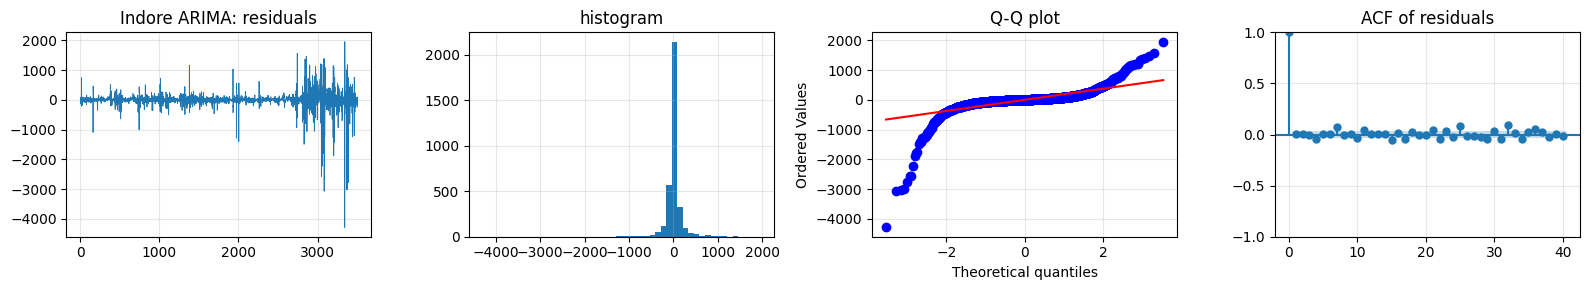

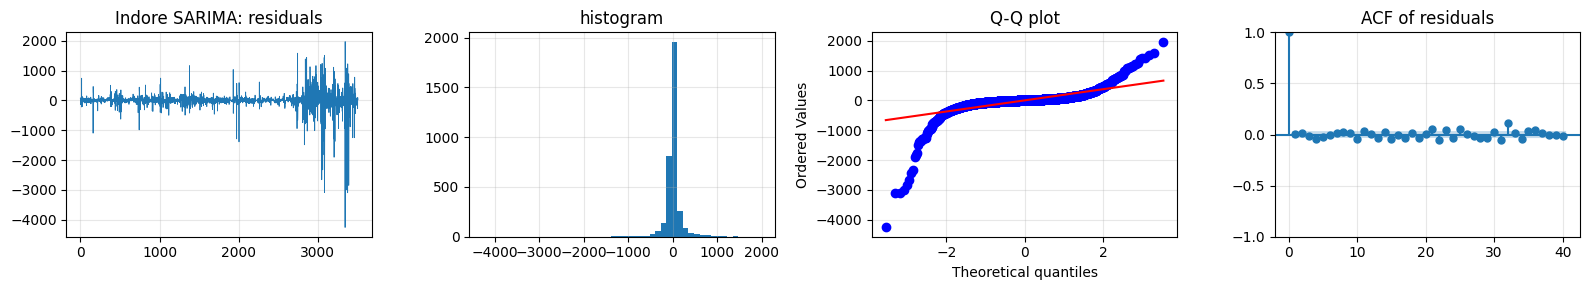

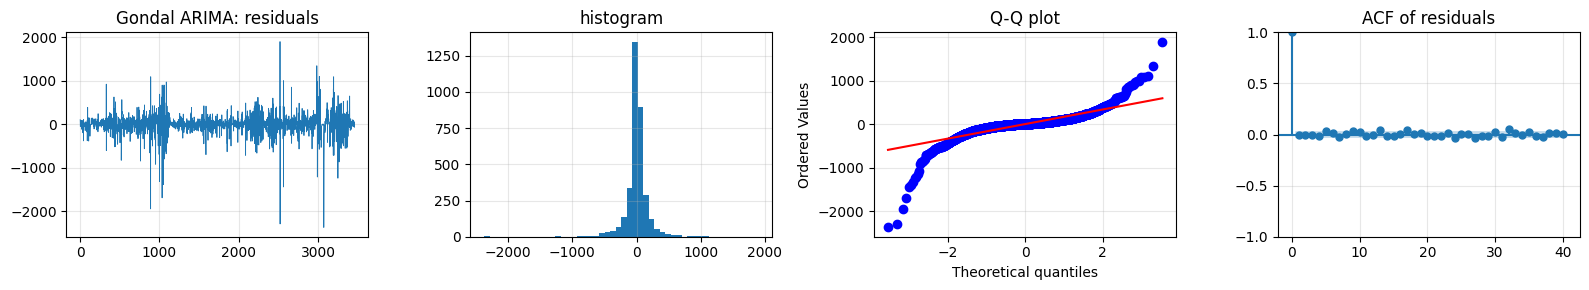

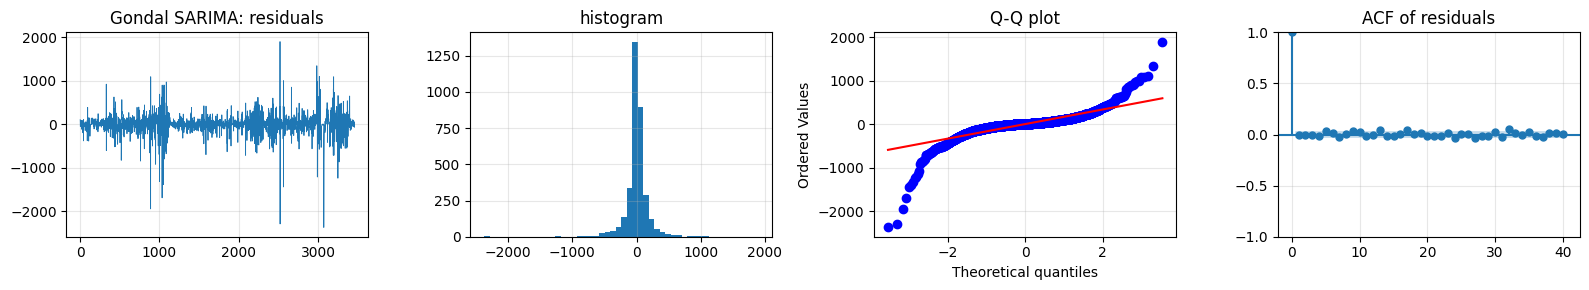

,market,model,mean,std,skew,kurtosis,Jarque-Bera,JB p-value,ARCH-LM,ARCH p-value
0,Indore,ARIMA,2.0580,250.7038,-4.2138,63.4224,596437.7397,0.0,294.9973,0.0
1,Indore,SARIMA,1.7512,251.0438,-4.2196,63.9214,605725.2299,0.0,292.7331,0.0
2,Gondal,ARIMA,2.1528,193.5012,-1.5572,27.2325,108021.7116,0.0,349.1335,0.0
3,Gondal,SARIMA,2.1528,193.5012,-1.5572,27.2325,108021.7116,0.0,349.1335,0.0


In [13]:
def resid_of(res, d): return pd.Series(res.resid).iloc[max(d, 1):].reset_index(drop=True)   # drop start-up values

RES = {}
rows = []
for m in MARKETS:
    for mod in ['ARIMA', 'SARIMA']:
        r = resid_of(FIT[(m, mod)], D_ORD[m]); RES[(m, mod)] = r
        jb = stats.jarque_bera(r); arch = het_arch(r, nlags=5)
        rows.append([m, mod, r.mean(), r.std(), r.skew(), r.kurt(), jb[0], jb[1], arch[0], arch[1]])
        fig, ax = plt.subplots(1, 4, figsize=(16, 3))
        r.plot(ax=ax[0], lw=.6, title=f'{m} {mod}: residuals'); ax[1].hist(r, bins=50); ax[1].set_title('histogram')
        stats.probplot(r, plot=ax[2]); ax[2].set_title('Q-Q plot'); plot_acf(r, lags=40, ax=ax[3], title='ACF of residuals')
        plt.tight_layout(); plt.show()
display(pd.DataFrame(rows, columns=['market', 'model', 'mean', 'std', 'skew', 'kurtosis', 'Jarque-Bera', 'JB p-value',
                                    'ARCH-LM', 'ARCH p-value']).round(4))

## 12. Ljung–Box test (residual autocorrelation)
**H₀:** residuals are white noise. p > 0.05 → no leftover autocorrelation (good model).

In [14]:
rows = []
for m in MARKETS:
    for mod in ['ARIMA', 'SARIMA']:
        fit = FIT[(m, mod)]; dfm = int(fit.model.k_ar + fit.model.k_ma) if hasattr(fit.model, 'k_ar') else 0
        lb = acorr_ljungbox(RES[(m, mod)], lags=[10, 20, 30], model_df=min(dfm, 9), return_df=True)
        for L, row in lb.iterrows(): rows.append([m, mod, L, row['lb_stat'], row['lb_pvalue'], 'no autocorrelation' if row['lb_pvalue'] > .05 else 'autocorrelation left'])
LB = pd.DataFrame(rows, columns=['market', 'model', 'lag', 'LB stat', 'p-value', 'conclusion (5%)']).round(4)
display(LB)

,market,model,lag,LB stat,p-value,conclusion (5%)
0,Indore,ARIMA,10,28.1246,0.0000,autocorrelation left
1,Indore,ARIMA,20,54.2207,0.0000,autocorrelation left
2,Indore,ARIMA,30,111.9081,0.0000,autocorrelation left
3,Indore,SARIMA,10,21.2368,0.0017,autocorrelation left
4,Indore,SARIMA,20,47.3184,0.0001,autocorrelation left
5,Indore,SARIMA,30,96.8625,0.0000,autocorrelation left
6,Gondal,ARIMA,10,13.0342,0.1107,no autocorrelation
7,Gondal,ARIMA,20,32.7089,0.0181,autocorrelation left
8,Gondal,ARIMA,30,46.1192,0.0169,autocorrelation left
9,Gondal,SARIMA,10,13.0342,0.1107,no autocorrelation


## 13. Test forecasts and error measures (MAE, RMSE, R², MAPE)
Two kinds of test forecasts for the 20% test sample:
* **Static multi-step** (as in the template): forecast the whole test period from the end of the training data — hard, long horizon.
* **Rolling 1-step-ahead:** parameters fixed from training, but each day's forecast uses all actual prices up to the previous day — this is what the DM test and the month-wise / rise-fall analysis use.

The **Naive** benchmark is "tomorrow = today" (1-step) and "flat last training value" (static).

In [15]:
def metrics(a, f):
    a, f = np.asarray(a, float), np.asarray(f, float); nz = a != 0
    return dict(MAE=mean_absolute_error(a, f), RMSE=np.sqrt(mean_squared_error(a, f)), R2=r2_score(a, f),
                MAPE_pct=np.mean(np.abs((a[nz] - f[nz]) / a[nz])) * 100)

F1, F1CI, FS, FSCI = {}, {}, {}, {}        # 1-step forecasts / CI ; static forecasts / CI
for m in MARKETS:
    n, ntr = len(V[m]), NTR[m]
    for mod in ['ARIMA', 'SARIMA']:
        res = FIT[(m, mod)]
        r2 = res.apply(V[m], refit=False)                           # same parameters, data up to every day
        p1 = r2.get_prediction(start=ntr, dynamic=False)
        F1[(m, mod)] = np.asarray(p1.predicted_mean); F1CI[(m, mod)] = np.asarray(p1.conf_int(alpha=.05))
        fs = res.get_forecast(steps=n - ntr)
        FS[(m, mod)] = np.asarray(fs.predicted_mean); FSCI[(m, mod)] = np.asarray(fs.conf_int(alpha=.05))
    F1[(m, 'Naive')] = V[m][ntr-1:-1]; FS[(m, 'Naive')] = np.full(n - ntr, V[m][ntr-1])

rows = []
for m in MARKETS:
    for mod in ['ARIMA', 'SARIMA', 'Naive']:
        rows.append([m, mod, '1-step rolling'] + list(metrics(TEST[m], F1[(m, mod)]).values()))
        rows.append([m, mod, 'static multi-step'] + list(metrics(TEST[m], FS[(m, mod)]).values()))
ERR = pd.DataFrame(rows, columns=['market', 'model', 'forecast type', 'MAE', 'RMSE', 'R2', 'MAPE_pct']).round(4)
display(ERR)

,market,model,forecast type,MAE,RMSE,R2,MAPE_pct
0,Indore,ARIMA,1-step rolling,213.4217,383.5893,0.5028,5.5572
1,Indore,ARIMA,static multi-step,971.0518,1098.4617,-3.0776,24.2895
2,Indore,SARIMA,1-step rolling,212.0735,384.2101,0.5011,5.5285
3,Indore,SARIMA,static multi-step,963.7925,1091.5264,-3.0263,24.1178
4,Indore,Naive,1-step rolling,223.5806,438.7458,0.3495,5.6953
5,Indore,Naive,static multi-step,1011.7783,1137.3663,-3.3716,25.2520
6,Gondal,ARIMA,1-step rolling,62.3721,100.2018,0.9218,1.4586
7,Gondal,ARIMA,static multi-step,943.7419,1009.4502,-6.9397,22.4684
8,Gondal,SARIMA,1-step rolling,62.3721,100.2018,0.9218,1.4586
9,Gondal,SARIMA,static multi-step,943.7419,1009.4502,-6.9397,22.4684


## 14. Naive forecasting comparison

In [16]:
rows = []
for m in MARKETS:
    for typ in ['1-step rolling', 'static multi-step']:
        sub = ERR[(ERR.market == m) & (ERR['forecast type'] == typ)].set_index('model')
        for mod in ['ARIMA', 'SARIMA']:
            rows.append([m, typ, mod, sub.loc[mod, 'RMSE'], sub.loc['Naive', 'RMSE'],
                         sub.loc[mod, 'RMSE'] / sub.loc['Naive', 'RMSE'],
                         (1 - sub.loc[mod, 'RMSE'] / sub.loc['Naive', 'RMSE']) * 100,
                         (1 - sub.loc[mod, 'MAE'] / sub.loc['Naive', 'MAE']) * 100])
NAIVE = pd.DataFrame(rows, columns=['market', 'forecast type', 'model', 'RMSE', 'Naive RMSE', "Theil's U (RMSE ratio)",
                                    'RMSE improvement % vs naive', 'MAE improvement % vs naive']).round(3)
display(NAIVE)
print("Theil's U < 1 and a positive improvement % mean the model beats the naive forecast; negative means it is worse than 'no change'.")

,market,forecast type,model,RMSE,Naive RMSE,Theil's U (RMSE ratio),RMSE improvement % vs naive,MAE improvement % vs naive
0,Indore,1-step rolling,ARIMA,383.589,438.746,0.874,12.571,4.544
1,Indore,1-step rolling,SARIMA,384.210,438.746,0.876,12.430,5.147
2,Indore,static multi-step,ARIMA,1098.462,1137.366,0.966,3.421,4.025
3,Indore,static multi-step,SARIMA,1091.526,1137.366,0.960,4.030,4.743
4,Gondal,1-step rolling,ARIMA,100.202,106.179,0.944,5.629,-10.787
5,Gondal,1-step rolling,SARIMA,100.202,106.179,0.944,5.629,-10.787
6,Gondal,static multi-step,ARIMA,1009.450,1013.310,0.996,0.381,0.435
7,Gondal,static multi-step,SARIMA,1009.450,1013.310,0.996,0.381,0.435


Theil's U < 1 and a positive improvement % mean the model beats the naive forecast; negative means it is worse than 'no change'.


## 15. Diebold–Mariano (DM) test
Compares the **1-step-ahead forecast errors** of two models. **H₀:** equal forecast accuracy. DM statistic with the Harvey–Leybourne–Newbold small-sample correction (t-distribution).
DM < 0 and p < 0.05 → model A is significantly better; DM > 0 and p < 0.05 → model B is better.

In [17]:
def dm_test(e1, e2, h=1, loss='squared'):
    e1, e2 = np.asarray(e1, float), np.asarray(e2, float)
    d = (e1**2 - e2**2) if loss == 'squared' else (np.abs(e1) - np.abs(e2))
    T = len(d); dbar = d.mean(); dc = d - dbar
    lrv = np.sum(dc * dc) / T
    for k in range(1, h): lrv += 2 * np.sum(dc[k:] * dc[:-k]) / T
    if lrv <= 0: return np.nan, 1.0, T                               # identical forecasts
    dm = dbar / np.sqrt(lrv / T) * np.sqrt((T + 1 - 2*h + h*(h-1)/T) / T)
    return dm, 2 * (1 - stats.t.cdf(abs(dm), df=T - 1)), T

rows = []
for m in MARKETS:
    err = {mod: TEST[m] - F1[(m, mod)] for mod in ['ARIMA', 'SARIMA', 'Naive']}
    for A, B in [('ARIMA', 'SARIMA'), ('ARIMA', 'Naive'), ('SARIMA', 'Naive')]:
        for L in ['squared', 'absolute']:
            s, p, T = dm_test(err[A], err[B], 1, L)
            verdict = 'identical forecasts' if np.isnan(s) else (('no significant difference') if p >= .05 else (f'{A} better' if s < 0 else f'{B} better'))
            rows.append([m, f'{A} vs {B}', L, s, p, T, verdict])
DM = pd.DataFrame(rows, columns=['market', 'A vs B', 'loss', 'DM stat', 'p-value', 'n', 'conclusion (5%)']).round(4)
display(DM)

,market,A vs B,loss,DM stat,p-value,n,conclusion (5%)
0,Indore,ARIMA vs SARIMA,squared,-0.4632,0.6433,878,no significant difference
1,Indore,ARIMA vs SARIMA,absolute,1.1785,0.2389,878,no significant difference
2,Indore,ARIMA vs Naive,squared,-3.7536,0.0002,878,ARIMA better
3,Indore,ARIMA vs Naive,absolute,-1.4481,0.1480,878,no significant difference
4,Indore,SARIMA vs Naive,squared,-3.6827,0.0002,878,SARIMA better
5,Indore,SARIMA vs Naive,absolute,-1.6264,0.1042,878,no significant difference
6,Gondal,ARIMA vs SARIMA,squared,NaN,1.0000,866,identical forecasts
7,Gondal,ARIMA vs SARIMA,absolute,NaN,1.0000,866,identical forecasts
8,Gondal,ARIMA vs Naive,squared,-1.3885,0.1653,866,no significant difference
9,Gondal,ARIMA vs Naive,absolute,4.0716,0.0001,866,Naive better


## 16. Rolling-origin backtesting
Expanding window: the model (orders fixed from section 8/9) is **re-estimated at each of `N_FOLDS` origins** across the test period and used to forecast the next `ROLL_H` observations. Reported: average error over all origins.

Rolling-origin backtest done in 81s (8 origins x 10-step horizon)


MAE    RMSE  MAPE_pct
market model                           
Gondal ARIMA    92.42  108.91      2.05
       Naive    95.94  112.04      2.12
       SARIMA   92.42  108.91      2.05
Indore ARIMA   202.71  276.95      4.60
       Naive   170.41  257.83      3.88
       SARIMA  203.67  277.63      4.63

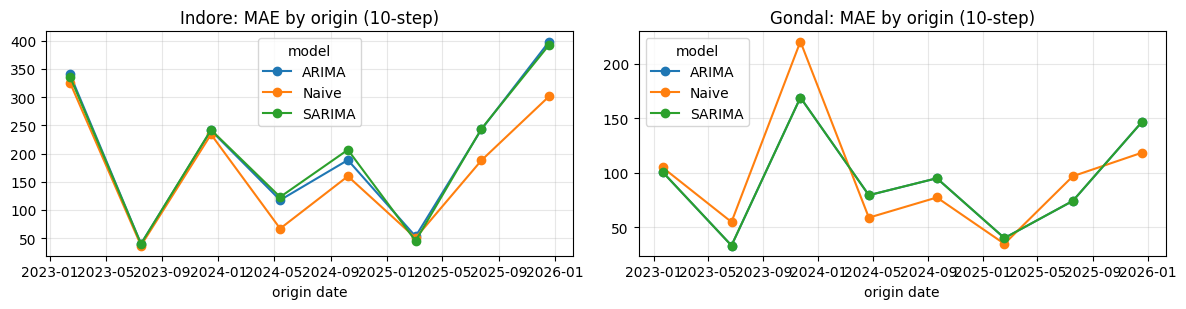

In [18]:
def rolling_origin(m):
    n, ntr = len(V[m]), NTR[m]; y = V[m]
    origins = np.linspace(ntr, n - ROLL_H, N_FOLDS).astype(int)
    out = []
    for o in origins:
        act = y[o:o + ROLL_H]
        fc = {'ARIMA': fit_sx(y[:o], BEST_ARIMA[m]).forecast(ROLL_H),
              'SARIMA': fit_sx(y[:o], BEST_SARIMA[m][0], BEST_SARIMA[m][1]).forecast(ROLL_H),
              'Naive': np.full(ROLL_H, y[o - 1])}
        for mod, f in fc.items():
            mt = metrics(act, f); out.append([m, DATES[m][o].date(), mod, mt['MAE'], mt['RMSE'], mt['MAPE_pct']])
    return pd.DataFrame(out, columns=['market', 'origin date', 'model', 'MAE', 'RMSE', 'MAPE_pct'])

t0 = time.time()
RO = pd.concat([rolling_origin(m) for m in MARKETS], ignore_index=True)
print(f'Rolling-origin backtest done in {time.time()-t0:.0f}s ({N_FOLDS} origins x {ROLL_H}-step horizon)')
RO_SUM = RO.groupby(['market', 'model'])[['MAE', 'RMSE', 'MAPE_pct']].mean().round(2)
display(RO_SUM)
fig, ax = plt.subplots(1, len(MARKETS), figsize=(6 * len(MARKETS), 3.2))
for a, m in zip(np.atleast_1d(ax), MARKETS):
    RO[RO.market == m].pivot(index='origin date', columns='model', values='MAE').plot(ax=a, marker='o', title=f'{m}: MAE by origin ({ROLL_H}-step)')
plt.tight_layout(); plt.show()

## 17. Actual vs predicted price graphs

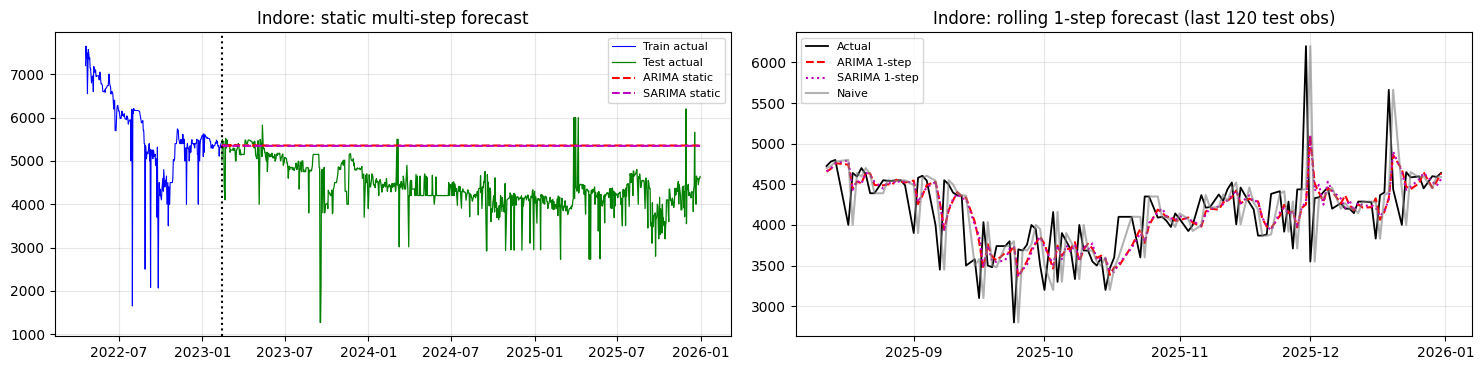

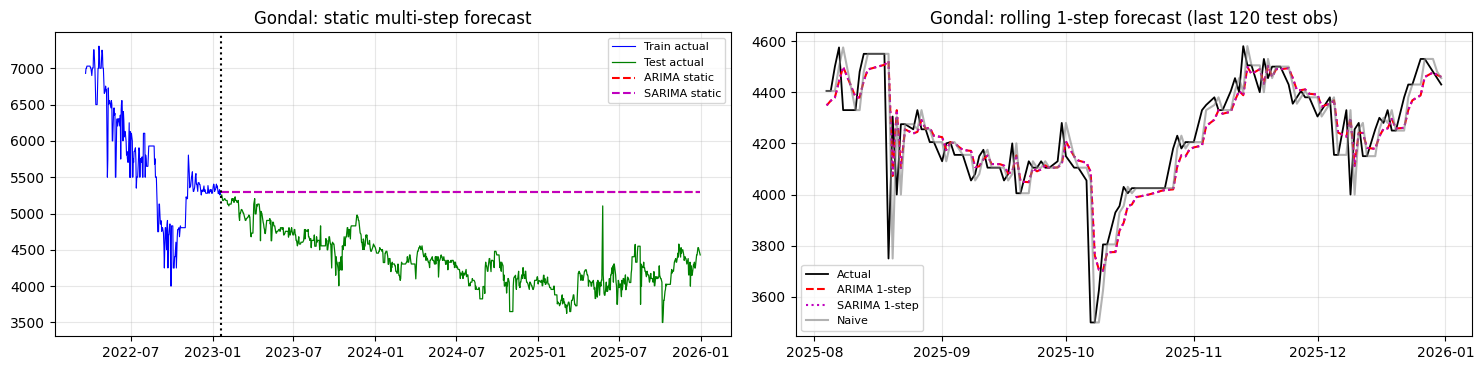

In [19]:
for m in MARKETS:
    idx = DATES[m][NTR[m]:]
    fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
    ax[0].plot(DATES[m][:NTR[m]][-250:], TRAIN[m][-250:], color='blue', lw=.8, label='Train actual')
    ax[0].plot(idx, TEST[m], color='green', lw=.9, label='Test actual')
    ax[0].plot(idx, FS[(m, 'ARIMA')], 'r--', label='ARIMA static'); ax[0].plot(idx, FS[(m, 'SARIMA')], 'm--', label='SARIMA static')
    ax[0].axvline(idx[0], color='k', ls=':'); ax[0].set_title(f'{m}: static multi-step forecast'); ax[0].legend(fontsize=8)
    z = slice(-120, None)
    ax[1].plot(idx[z], TEST[m][z], color='black', lw=1.3, label='Actual')
    ax[1].plot(idx[z], F1[(m, 'ARIMA')][z], 'r--', label='ARIMA 1-step'); ax[1].plot(idx[z], F1[(m, 'SARIMA')][z], 'm:', label='SARIMA 1-step')
    ax[1].plot(idx[z], F1[(m, 'Naive')][z], color='grey', alpha=.6, label='Naive'); ax[1].set_title(f'{m}: rolling 1-step forecast (last 120 test obs)'); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

## 18. Forecast confidence intervals (95%)

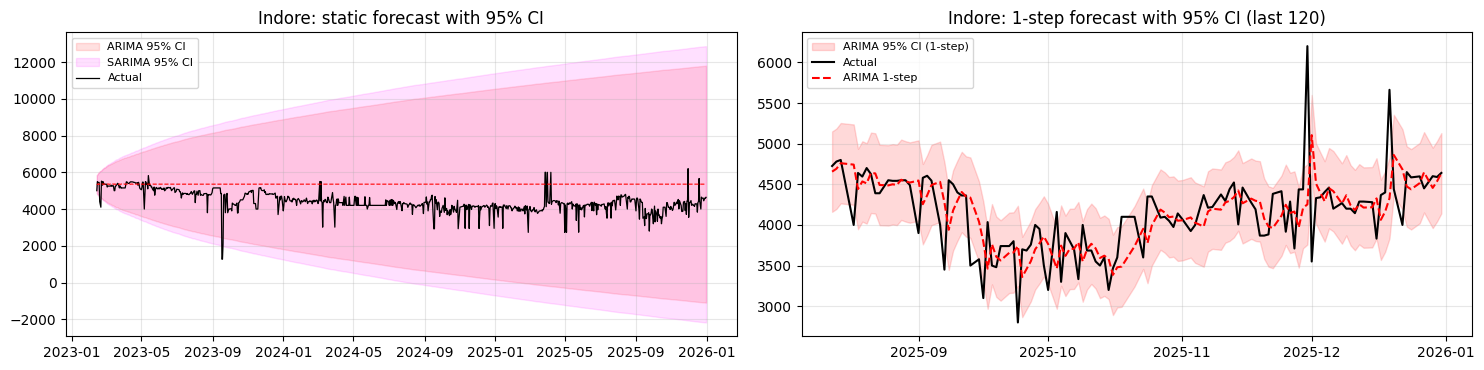

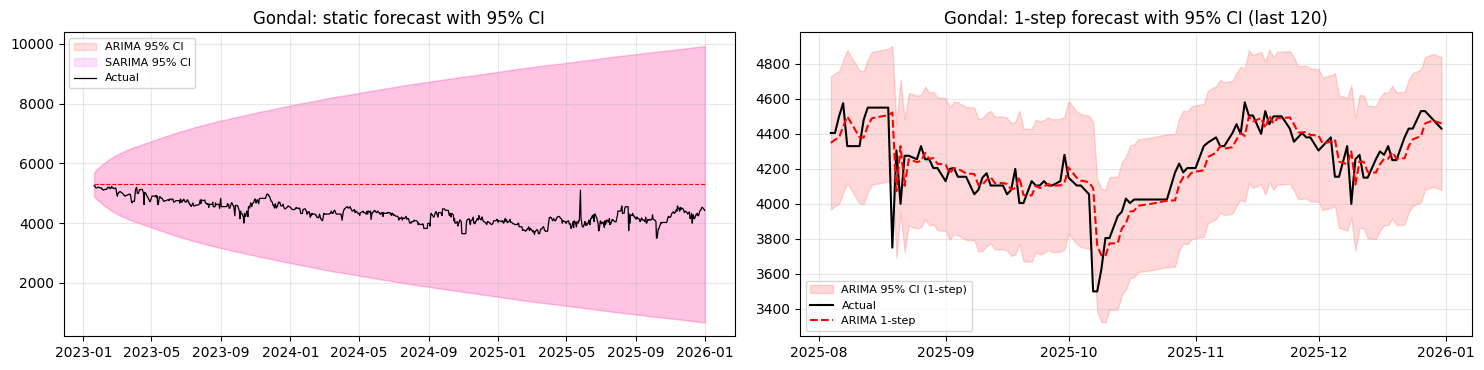

,market,model,1-step coverage %,1-step mean width,static coverage %,static mean width
0,Indore,ARIMA,89.5,989.2,99.4,8643.0
1,Indore,SARIMA,89.9,988.6,99.5,10029.4
2,Gondal,ARIMA,99.1,758.4,100.0,6205.5
3,Gondal,SARIMA,99.1,758.4,100.0,6205.5


A good 95% interval should cover about 95% of the actual prices.


In [20]:
rows = []
for m in MARKETS:
    idx = DATES[m][NTR[m]:]
    fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
    for mod, col in [('ARIMA', 'red'), ('SARIMA', 'magenta')]:
        ci = FSCI[(m, mod)]
        ax[0].fill_between(idx, ci[:, 0], ci[:, 1], color=col, alpha=.12, label=f'{mod} 95% CI')
        c1 = F1CI[(m, mod)]
        cov1 = np.mean((TEST[m] >= c1[:, 0]) & (TEST[m] <= c1[:, 1])) * 100
        covS = np.mean((TEST[m] >= ci[:, 0]) & (TEST[m] <= ci[:, 1])) * 100
        rows.append([m, mod, cov1, np.mean(c1[:, 1] - c1[:, 0]), covS, np.mean(ci[:, 1] - ci[:, 0])])
    ax[0].plot(idx, TEST[m], 'k', lw=.9, label='Actual'); ax[0].plot(idx, FS[(m, 'ARIMA')], 'r--', lw=.8); ax[0].set_title(f'{m}: static forecast with 95% CI'); ax[0].legend(fontsize=8)
    z = slice(-120, None); c = F1CI[(m, 'ARIMA')]
    ax[1].fill_between(idx[z], c[z, 0], c[z, 1], color='red', alpha=.15, label='ARIMA 95% CI (1-step)')
    ax[1].plot(idx[z], TEST[m][z], 'k', label='Actual'); ax[1].plot(idx[z], F1[(m, 'ARIMA')][z], 'r--', label='ARIMA 1-step'); ax[1].legend(fontsize=8)
    ax[1].set_title(f'{m}: 1-step forecast with 95% CI (last 120)')
    plt.tight_layout(); plt.show()
CI_TAB = pd.DataFrame(rows, columns=['market', 'model', '1-step coverage %', '1-step mean width', 'static coverage %', 'static mean width']).round(1)
display(CI_TAB); print('A good 95% interval should cover about 95% of the actual prices.')

## 19. Future soybean price forecasting
Both best models are re-fitted on the **full** data and used to forecast the next `FUTURE_H` trading days (Monday–Saturday as in the data, excluding the holiday list) with 95% intervals. Forecasts start after the last date in your files.

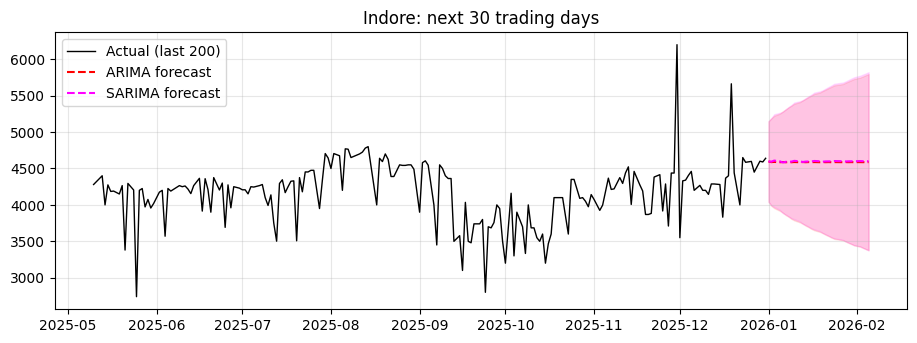

,ARIMA_forecast,ARIMA_lower95,ARIMA_upper95,SARIMA_forecast,SARIMA_lower95,SARIMA_upper95
date,,,,,,
2026-01-01,4595.3,4042.3,5148.3,4596.6,4043.4,5149.7
2026-01-02,4587.5,3987.1,5188.0,4594.2,3995.1,5193.3
2026-01-03,4590.3,3956.1,5224.5,4608.6,3971.9,5245.3
2026-01-05,4585.8,3917.9,5253.7,4597.8,3930.5,5265.2
2026-01-06,4589.1,3893.5,5284.8,4582.6,3887.2,5278.0
2026-01-07,4585.6,3860.7,5310.6,4591.4,3869.6,5313.3
2026-01-08,4588.7,3838.4,5339.0,4593.1,3842.4,5343.8
2026-01-09,4585.8,3808.7,5362.9,4594.2,3817.8,5370.6


...


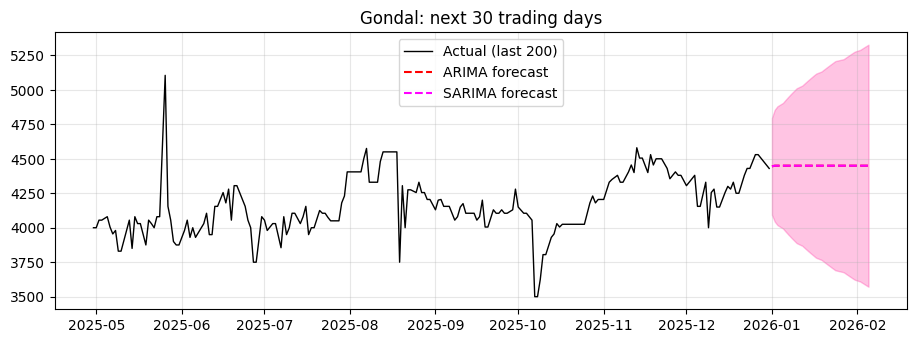

,ARIMA_forecast,ARIMA_lower95,ARIMA_upper95,SARIMA_forecast,SARIMA_lower95,SARIMA_upper95
date,,,,,,
2026-01-01,4445.0,4094.0,4796.0,4445.0,4094.0,4796.0
2026-01-02,4449.8,4044.8,4854.8,4449.8,4044.8,4854.8
2026-01-03,4449.8,4018.9,4880.7,4449.8,4018.9,4880.7
2026-01-05,4449.8,3994.5,4905.1,4449.8,3994.5,4905.1
2026-01-06,4449.8,3971.3,4928.3,4449.8,3971.3,4928.3
2026-01-07,4449.8,3949.2,4950.4,4449.8,3949.2,4950.4
2026-01-08,4449.8,3928.0,4971.6,4449.8,3928.0,4971.6
2026-01-09,4449.8,3907.7,4991.9,4449.8,3907.7,4991.9


...


In [21]:
def future_dates(last, k, allowed):
    out, d = [], last
    while len(out) < k:
        d += pd.Timedelta('1D')
        if d.dayofweek in allowed and d not in set(HOL): out.append(d)
    return pd.DatetimeIndex(out)

FUT = {}
for m in MARKETS:
    allowed = set(DATES[m].dayofweek) - ({6} if (DATES[m].dayofweek == 6).mean() < .05 else set())
    fd = future_dates(DATES[m][-1], FUTURE_H, allowed); parts = []
    for mod in ['ARIMA', 'SARIMA']:
        spec = (BEST_ARIMA[m], (0, 0, 0, 0)) if mod == 'ARIMA' else BEST_SARIMA[m]
        full = fit_sx(V[m], spec[0], spec[1]); fc = full.get_forecast(FUTURE_H); ci = np.asarray(fc.conf_int(alpha=.05))
        parts.append(pd.DataFrame({f'{mod}_forecast': np.asarray(fc.predicted_mean), f'{mod}_lower95': ci[:, 0], f'{mod}_upper95': ci[:, 1]}, index=fd))
    FUT[m] = pd.concat(parts, axis=1).round(1); FUT[m].index.name = 'date'
    fig, ax = plt.subplots(figsize=(11, 3.6))
    ax.plot(DATES[m][-200:], V[m][-200:], 'k', lw=1, label='Actual (last 200)')
    for mod, col in [('ARIMA', 'red'), ('SARIMA', 'magenta')]:
        ax.plot(fd, FUT[m][f'{mod}_forecast'], color=col, ls='--', label=f'{mod} forecast')
        ax.fill_between(fd, FUT[m][f'{mod}_lower95'], FUT[m][f'{mod}_upper95'], color=col, alpha=.12)
    ax.set_title(f'{m}: next {FUTURE_H} trading days'); ax.legend(); plt.show()
    display(FUT[m].head(8)); print('...')

## 20. Month-wise forecasting error analysis (rolling 1-step errors on the test sample)

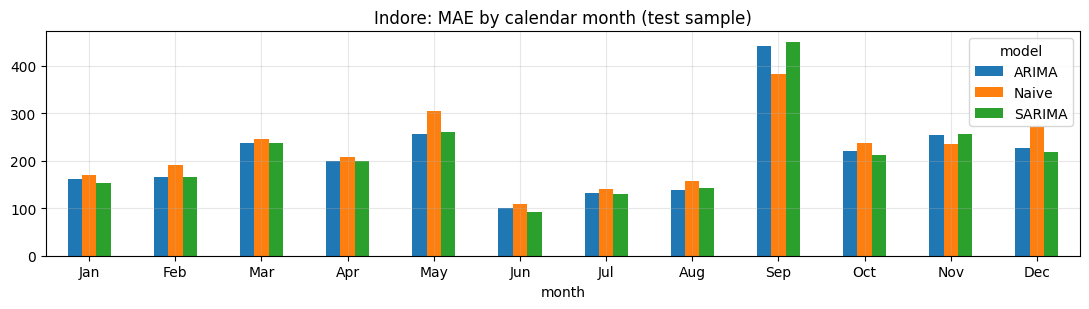

Indore: hardest months for ARIMA -> Sep, May, Nov | easiest -> Jun, Jul, Aug


MAE         MAPE_pct       
model   ARIMA  SARIMA    ARIMA SARIMA
month                                
Jan    162.35  154.19     4.09   3.89
Feb    166.24  165.95     4.02   4.01
Mar    237.52  238.23     5.45   5.47
Apr    199.58  198.71     4.27   4.25
May    256.80  261.15     6.50   6.60
Jun     99.57   91.21     2.34   2.15
Jul    132.32  130.78     3.14   3.10
Aug    139.33  141.87     3.22   3.28
Sep    442.37  450.51    15.37  15.61
Oct    221.17  212.43     5.72   5.50
Nov    254.17  256.12     6.03   6.09
Dec    226.19  218.28     5.79   5.58

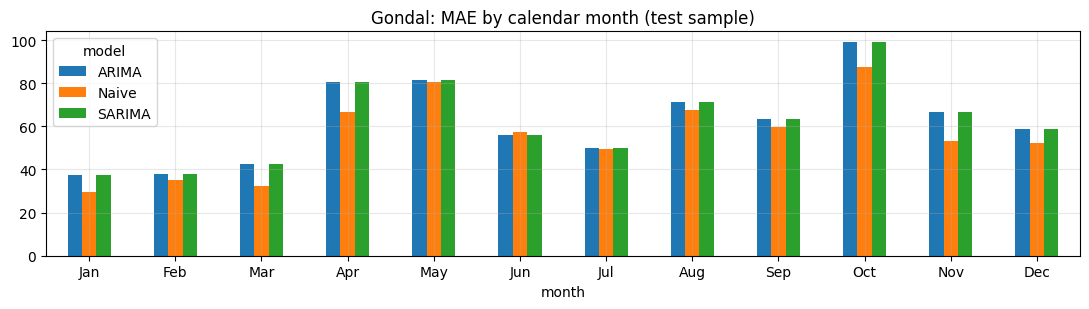

Gondal: hardest months for ARIMA -> Oct, May, Apr | easiest -> Jan, Feb, Mar


MAE        MAPE_pct       
model  ARIMA SARIMA    ARIMA SARIMA
month                              
Jan    37.58  37.58     0.87   0.87
Feb    37.85  37.85     0.90   0.90
Mar    42.69  42.69     1.00   1.00
Apr    80.74  80.74     1.79   1.79
May    81.60  81.60     1.87   1.87
Jun    55.77  55.77     1.33   1.33
Jul    49.78  49.78     1.17   1.17
Aug    71.31  71.31     1.69   1.69
Sep    63.37  63.37     1.47   1.47
Oct    99.08  99.08     2.43   2.43
Nov    66.81  66.81     1.55   1.55
Dec    58.66  58.66     1.36   1.36

In [22]:
MONTH = {}
mnames = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
for m in MARKETS:
    idx = DATES[m][NTR[m]:]; rows = []
    for mod in ['ARIMA', 'SARIMA', 'Naive']:
        e = pd.Series(TEST[m] - F1[(m, mod)], index=idx); a = pd.Series(TEST[m], index=idx)
        g = pd.DataFrame({'e': e, 'ae': e.abs(), 'se': e**2, 'ape': (e.abs() / a) * 100, 'mon': idx.month}).groupby('mon')
        t = pd.DataFrame({'MAE': g.ae.mean(), 'RMSE': np.sqrt(g.se.mean()), 'MAPE_pct': g.ape.mean(), 'bias (mean error)': g.e.mean(), 'n': g.e.size()})
        t.insert(0, 'model', mod); t.insert(0, 'month', [mnames[i - 1] for i in t.index]); rows.append(t.reset_index(drop=True))
    MONTH[m] = pd.concat(rows, ignore_index=True).round(2)
    piv = MONTH[m].pivot(index='month', columns='model', values='MAE').reindex(mnames)
    fig, ax = plt.subplots(figsize=(11, 3.2)); piv.plot.bar(ax=ax, rot=0, title=f'{m}: MAE by calendar month (test sample)'); plt.tight_layout(); plt.show()
    worst = MONTH[m][MONTH[m].model == 'ARIMA'].sort_values('MAE', ascending=False).head(3)
    print(f"{m}: hardest months for ARIMA -> {', '.join(worst.month)} | easiest -> {MONTH[m][MONTH[m].model=='ARIMA'].sort_values('MAE').head(3).month.str.cat(sep=', ')}")
    display(MONTH[m][MONTH[m].model.isin(['ARIMA', 'SARIMA'])].pivot(index='month', columns='model', values=['MAE', 'MAPE_pct']).reindex(mnames))

## 21. Price rise / fall prediction accuracy
For every test day: **actual move** = today − yesterday; **predicted move** = 1-step forecast − yesterday. Accuracy is measured on days when the price really **rose or fell** (flat days are excluded because they have no direction; the share of flat days is reported). The benchmark "same direction as yesterday" is shown too.

In [23]:
DIR, CM = [], {}
for m in MARKETS:
    prev = V[m][NTR[m]-1:-1]; act = np.sign(TEST[m] - prev); nz = act != 0
    prev_dir = np.sign(V[m][NTR[m]-1:-1] - V[m][NTR[m]-2:-2])
    flat = (act == 0).mean() * 100
    for mod in ['ARIMA', 'SARIMA', 'Prev-direction']:
        pred = prev_dir if mod == 'Prev-direction' else np.sign(F1[(m, mod)] - prev)
        ok = nz & (pred != 0)
        acc = np.mean(pred[ok] == act[ok]) * 100
        cm = confusion_matrix(act[ok], pred[ok], labels=[-1, 1]); CM[(m, mod)] = cm
        rec_fall = cm[0, 0] / max(cm[0].sum(), 1) * 100; rec_rise = cm[1, 1] / max(cm[1].sum(), 1) * 100
        prc_fall = cm[0, 0] / max(cm[:, 0].sum(), 1) * 100; prc_rise = cm[1, 1] / max(cm[:, 1].sum(), 1) * 100
        DIR.append([m, mod, ok.sum(), acc, rec_rise, prc_rise, rec_fall, prc_fall, flat])
DIR = pd.DataFrame(DIR, columns=['market', 'model', 'n (rise/fall days)', 'direction accuracy %', 'rise recall %', 'rise precision %',
                                 'fall recall %', 'fall precision %', 'flat days in test %']).round(1)
display(DIR)
for m in MARKETS:
    print(f'{m} confusion matrix, ARIMA (rows = actual fall/rise, cols = predicted fall/rise):'); print(CM[(m, 'ARIMA')])

,market,model,n (rise/fall days),direction accuracy %,rise recall %,rise precision %,fall recall %,fall precision %,flat days in test %
0,Indore,ARIMA,732,65.6,59.2,68.4,72.1,63.3,16.6
1,Indore,SARIMA,732,66.3,58.6,69.8,74.0,63.7,16.6
2,Indore,Prev-direction,655,35.6,36.6,36.6,34.5,34.5,16.6
3,Gondal,ARIMA,550,60.0,62.6,57.3,57.6,62.9,36.5
4,Gondal,SARIMA,550,60.0,62.6,57.3,57.6,62.9,36.5
5,Gondal,Prev-direction,344,39.0,38.4,35.3,39.5,42.7,36.5


Indore confusion matrix, ARIMA (rows = actual fall/rise, cols = predicted fall/rise):
[[261 101]
 [151 219]]
Gondal confusion matrix, ARIMA (rows = actual fall/rise, cols = predicted fall/rise):
[[166 122]
 [ 98 164]]


## 22. Final ARIMA vs SARIMA comparison table

In [24]:
rows = []
for m in MARKETS:
    for mod in ['ARIMA', 'SARIMA']:
        spec = f'ARIMA{BEST_ARIMA[m]}' if mod == 'ARIMA' else f'SARIMA{BEST_SARIMA[m][0]}x{BEST_SARIMA[m][1]}'
        r1 = ERR[(ERR.market == m) & (ERR.model == mod) & (ERR['forecast type'] == '1-step rolling')].iloc[0]
        rs = ERR[(ERR.market == m) & (ERR.model == mod) & (ERR['forecast type'] == 'static multi-step')].iloc[0]
        lb = LB[(LB.market == m) & (LB.model == mod) & (LB.lag == 20)]['p-value'].iloc[0]
        dmr = DM[(DM.market == m) & (DM['A vs B'] == f'{mod} vs Naive') & (DM.loss == 'squared')]['conclusion (5%)'].iloc[0]
        dma = DM[(DM.market == m) & (DM['A vs B'] == 'ARIMA vs SARIMA') & (DM.loss == 'squared')]['conclusion (5%)'].iloc[0]
        ro = RO_SUM.loc[(m, mod)]; dr = DIR[(DIR.market == m) & (DIR.model == mod)]['direction accuracy %'].iloc[0]
        rows.append([m, spec, IC_TABLE[(IC_TABLE.market == m) & (IC_TABLE.model == mod)].AIC.iloc[0], IC_TABLE[(IC_TABLE.market == m) & (IC_TABLE.model == mod)].BIC.iloc[0],
                     r1.MAE, r1.RMSE, r1.R2, r1.MAPE_pct, rs.MAE, rs.RMSE, rs.R2, rs.MAPE_pct, ro['RMSE'], dr, lb, dmr, dma])
FINAL = pd.DataFrame(rows, columns=['market', 'model (specification)', 'AIC', 'BIC', 'MAE (1-step)', 'RMSE (1-step)', 'R2 (1-step)', 'MAPE % (1-step)',
                                    'MAE (static)', 'RMSE (static)', 'R2 (static)', 'MAPE % (static)', f'RollOrigin RMSE ({ROLL_H}-step)',
                                    'rise/fall accuracy %', 'Ljung-Box p (lag 20)', 'DM vs Naive (sq. loss)', 'DM ARIMA vs SARIMA (sq. loss)']).round(3)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
display(FINAL)
for m in MARKETS:
    f = FINAL[FINAL.market == m].set_index('model (specification)')
    best = f['RMSE (1-step)'].idxmin()
    print(f"{m}: lowest 1-step RMSE -> {best}; lowest AIC -> {f['AIC'].idxmin()}; lowest BIC -> {f['BIC'].idxmin()}")

,market,model (specification),AIC,BIC,MAE (1-step),RMSE (1-step),R2 (1-step),MAPE % (1-step),MAE (static),RMSE (static),R2 (static),MAPE % (static),RollOrigin RMSE (10-step),rise/fall accuracy %,Ljung-Box p (lag 20),DM vs Naive (sq. loss),DM ARIMA vs SARIMA (sq. loss)
0,Indore,"ARIMA(2, 1, 3)",48711.7,48748.7,213.422,383.589,0.503,5.557,971.052,1098.462,-3.078,24.290,276.95,65.6,0.000,ARIMA better,no significant difference
1,Indore,"SARIMA(2, 1, 2)x(1, 0, 1, 6)",48722.9,48766.0,212.074,384.210,0.501,5.528,963.792,1091.526,-3.026,24.118,277.63,66.3,0.000,SARIMA better,no significant difference
2,Gondal,"ARIMA(0, 1, 2)",46273.9,46292.4,62.372,100.202,0.922,1.459,943.742,1009.450,-6.940,22.468,108.91,60.0,0.018,no significant difference,identical forecasts
3,Gondal,"SARIMA(0, 1, 2)x(0, 0, 0, 6)",46273.9,46292.4,62.372,100.202,0.922,1.459,943.742,1009.450,-6.940,22.468,108.91,60.0,0.018,no significant difference,identical forecasts


Indore: lowest 1-step RMSE -> ARIMA(2, 1, 3); lowest AIC -> ARIMA(2, 1, 3); lowest BIC -> ARIMA(2, 1, 3)
Gondal: lowest 1-step RMSE -> ARIMA(0, 1, 2); lowest AIC -> ARIMA(0, 1, 2); lowest BIC -> ARIMA(0, 1, 2)


## 23. Export all forecast results to Excel

In [25]:
OUT = 'soybean_arima_sarima_results.xlsx'
with pd.ExcelWriter(OUT, engine='openpyxl') as xw:
    FINAL.to_excel(xw, sheet_name='Final_comparison', index=False)
    ERR.to_excel(xw, sheet_name='Error_measures', index=False); NAIVE.to_excel(xw, sheet_name='Naive_comparison', index=False)
    DM.to_excel(xw, sheet_name='DM_test', index=False); IC_TABLE.to_excel(xw, sheet_name='AIC_BIC', index=False); LB.to_excel(xw, sheet_name='Ljung_Box', index=False)
    RO.to_excel(xw, sheet_name='Rolling_origin', index=False); DIR.to_excel(xw, sheet_name='Rise_fall_accuracy', index=False); CI_TAB.to_excel(xw, sheet_name='CI_coverage', index=False)
    pd.DataFrame({'setting': ['PRICE_COL', 'TEST_FRAC', 'IC', 'ROLL_WINDOW', 'N_FOLDS', 'ROLL_H', 'FUTURE_H', 'REMOVE_COVID', 'REMOVE_HOLIDAYS', 'seasonal m'],
                  'value': [PRICE_COL, TEST_FRAC, IC, ROLL_WINDOW, N_FOLDS, ROLL_H, FUTURE_H, REMOVE_COVID, REMOVE_HOLIDAYS, str(M_SEAS)]}).to_excel(xw, sheet_name='Settings', index=False)
    for m in MARKETS:
        idx = DATES[m][NTR[m]:]
        t = pd.DataFrame({'date': idx, 'actual': TEST[m],
                          'ARIMA_1step': F1[(m, 'ARIMA')], 'ARIMA_1step_lower95': F1CI[(m, 'ARIMA')][:, 0], 'ARIMA_1step_upper95': F1CI[(m, 'ARIMA')][:, 1],
                          'SARIMA_1step': F1[(m, 'SARIMA')], 'SARIMA_1step_lower95': F1CI[(m, 'SARIMA')][:, 0], 'SARIMA_1step_upper95': F1CI[(m, 'SARIMA')][:, 1],
                          'Naive_1step': F1[(m, 'Naive')],
                          'ARIMA_static': FS[(m, 'ARIMA')], 'ARIMA_static_lower95': FSCI[(m, 'ARIMA')][:, 0], 'ARIMA_static_upper95': FSCI[(m, 'ARIMA')][:, 1],
                          'SARIMA_static': FS[(m, 'SARIMA')], 'SARIMA_static_lower95': FSCI[(m, 'SARIMA')][:, 0], 'SARIMA_static_upper95': FSCI[(m, 'SARIMA')][:, 1]}).round(2)
        t.to_excel(xw, sheet_name=f'{m}_test_forecasts', index=False)
        FUT[m].reset_index().to_excel(xw, sheet_name=f'{m}_future_forecast', index=False)
        MONTH[m].to_excel(xw, sheet_name=f'{m}_monthwise_error', index=False)
        ARIMA_GRID[m].astype({'order': str}).round(2).to_excel(xw, sheet_name=f'{m}_ARIMA_grid', index=False)
        SARIMA_GRID[m].astype({'order': str, 'seasonal_order': str}).round(2).to_excel(xw, sheet_name=f'{m}_SARIMA_grid', index=False)
print('Saved', OUT)
try: files.download(OUT)
except Exception: print('Download the file from the Colab file panel (folder icon on the left).')

Saved soybean_arima_sarima_results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### How to read the results
* **AIC / BIC:** lower is better; BIC penalises extra parameters more. If SARIMA's AIC gain is tiny, the seasonal terms add little.
* **MAE, RMSE, MAPE:** smaller is better. **R²** on price levels is high for any persistent series, so judge models by the comparison with **Naive** (Theil's U < 1) and by the **DM test**.
* **Static multi-step vs 1-step:** the static forecast over ~20% of the sample (years) cannot follow price shocks, so its errors are large; the 1-step and rolling-origin results are the practical accuracy.
* **Ljung–Box p > 0.05:** residuals have no leftover autocorrelation.
* **SARIMA = ARIMA?** If the best seasonal order found is (0, 0, 0, m) the SARIMA model has no seasonal terms and is identical to ARIMA (forecasts identical, DM test says 'identical forecasts'). That itself is a finding: no weekly seasonality was supported by the data.
* **Forward-filled days** repeat the previous price, which makes "no change" hard to beat on absolute error — mention this when interpreting Naive.